### 1. Dataset Overview (Dataset: Diabetes)

In [30]:
from sklearn.datasets import load_diabetes

data = load_diabetes(as_frame=True)
df = data.frame

print(df)
print(f"Missing Values\n{df.isnull().sum()}\n")

print(f"Datatype Of Columns\n{df.dtypes}\n")

          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  target  
0   -0.002592  0.019907 -0.0176

### 2. Correlation Heatmap 

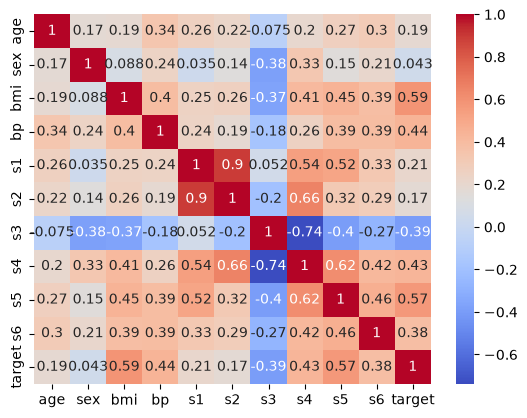

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = df.select_dtypes(include="number")

correlation = numeric_data.corr()

sns.heatmap(
    data=correlation,
    annot=True,
    cmap="coolwarm"
)
plt.show()

### 3. ColumnTransformer and Pipeline

In [29]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

data = load_diabetes(as_frame=True)

X = data.data
y = data.target

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_cols = list(X.columns)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
])

prep_pipeline = Pipeline([
    ("preprocessor", preprocessor),
])

X_train_processed = prep_pipeline.fit_transform(x_train)
X_test_processed = prep_pipeline.transform(x_test)

feature_names = prep_pipeline.named_steps["preprocessor"].get_feature_names_out()
print(f"Processed train shape: {X_train_processed.shape}")
print(f"Processed test shape : {X_test_processed.shape}")

print(f"\nFeature names: {feature_names}")
print(f"Total features: {len(feature_names)}")

Processed train shape: (353, 10)
Processed test shape : (89, 10)

Feature names: ['num__age' 'num__sex' 'num__bmi' 'num__bp' 'num__s1' 'num__s2' 'num__s3'
 'num__s4' 'num__s5' 'num__s6']
Total features: 10


### 4. Model Creation (LinearRegression)

In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {np.sqrt(mse):.2f}")
print(f"R2: {r2_score(y_test, y_pred):.3f}")
print(f"Train R2: {model.score(x_train, y_train):.3f}")

MAE: 42.79
MSE: 2900.19
RMSE: 53.85
R2: 0.453
Train R2: 0.528
